In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print("💻 ローカル / ホスト環境で実行中。ルート:", repo_root)


💻 ローカル / ホスト環境で実行中。ルート: /home/student/Documents/GitHub/study-mikanos


# 7.6 割り込みのまとめ (`Interrupt Flow Summary`)

本節では、名著『ゼロからのOS自作入門』（内田公太 著、マイナビ出版）の第7章「割り込みとFIFO」7.6節に基づき、第7章の前半（7.1〜7.5）で個別に構築してきた割り込みサブシステム群——**割り込みハンドラ (`__attribute__((interrupt))`)、割り込み記述子表 (IDT)、LIDT 命令、Local APIC、および PCI MSI (Message Signaled Interrupts)**——を統合し、**「ユーザーがマウスを動かした瞬間に、ハードウェアとOSカーネルの間で何がどの順序で起きるのか」** というエンド・ツー・エンド（E2E）の完全なライフサイクルフローを総括します。

> [!IMPORTANT]
> **本節の学習目標 (Learning Objectives)**:
> 1. **12 ステージ割り込みパイプラインの完全トレース**: マウスセンサ検知 $\to$ xHCI Event Ring $\to$ PCIe MSI $\to$ Local APIC $\to$ CPU $\to$ IDT $\to$ C++ ハンドラ $\to$ EOI $\to$ `IRETQ` 復帰に至る 12 段階のハードウェア・ソフトウェア協調動作を完全に理解する。
> 2. **ハードウェアとソフトウェアの責任分界点の明確化**: CPU シリコン/マイクロコードが自動実行する領域（スタック整列、`InterruptFrame` の push、IF フラグの自動クリア）と、OS/コンパイラが担当すべき領域（汎用レジスタ退避、イベント処理、EOI 通知、`iretq` 発行）の境界を厳密に区別する。
> 3. **x86-64 スタックフレームの 4 態ライフサイクル**: 通常実行時 $\to$ ハードウェア割り込み突入 $\to$ コンパイラ退避後 $\to$ `IRETQ` 復元後 におけるスタックポインタ（`RSP`）の 16 バイトアライメント推移を導出する。
> 4. **多重割り込み抑止 (CLI/STI) と EOI 通知の決定的な意義**: なぜハンドラ突入時にハードウェアが自動で IF フラグを 0 にするのか、そしてなぜ EOI (`0xFEE000B0`) を通知しないとシステムが永久デッドロックに陥るのかを論理的に解明する。


## 1. 割り込み発生から CPU 到達まで (Stages 1 〜 4)

ユーザーが机の上でマウスを動かした瞬間から、CPU コアが割り込みを認識するまでのハードウェアレベルの伝播経路を辿ります。

```
[マウス物理移動] 
       │ (1) USB HID インプットレポート (dx, dy)
       ▼
 [xHCI コントローラ]
       │ (2) Transfer Event TRB を Primary Event Ring へ書き込み
       │ (3) PCIe MSI Memory Write トランザクション生成 (Addr: 0xFEE00000, Data: 0xC040)
       ▼
 [システムバス / NoC]
       │
       ▼
 [Local APIC (Core 0)]
         (4) メッセージ受信、宛先照合、IRR (Interrupt Request Register) bit 64 セット
             INTR 信号線をアサートして CPU コアへ通知！
```

---

### Stage 1: マウスハードウェアイベント (Mouse Hardware Event)
1. ユーザーがマウスを動かすと、光学センサが変位 `(dx, dy)` を検知します。
2. マウス内部のマイクロコントローラが USB HID Boot Protocol に従い、ボタン状態（bit 0: 左, bit 1: 右, bit 2: 中）および 8 ビット符号付き変位 `dx`, `dy`（各 -128 〜 +127）を 3 バイトのパケットとして USB エンドポイントバッファへ格納します。

### Stage 2: xHCI Transfer Event TRB 格納 (xHCI Event Ring)
1. USB 3.0 ホストコントローラ（**xHCI: eXtensible Host Controller Interface**）は、インタラプトエンドポイントの周期（Polling Interval）に従いマウスからパケットを受信します。
2. xHCI は受信した変位データをメモリ内の **Primary Event Ring**（リングバッファ）へ 16 バイトの **Transfer Event TRB**（Type=32）として書き込み、Cycle Bit を反転させて OS に新規イベントの到着を知らせます。

### Stage 3: PCIe MSI メモリ書き込みトランザクション (PCIe MSI Memory Write)
1. xHCI は、第 7.5 節で設定した **MSI ケーパビリティレジスタ** を参照します：
   - **Message Address**: `0xFEE00000 | (bsp_apic_id << 12) = 0xFEE00000`
   - **Message Data**: `(kFixed << 8) | 0x40 | 0xC000 = 0xC040`
2. xHCI は PCIe バス（インターコネクト）に対して、物理アドレス `0xFEE00000` 宛てに値 `0xC040` を書き込む **Posted Memory Write Transaction** を発行します。
3. 物理ピン（INTA#等）による電圧変化ではなく、高帯域な PCIe パケットとして送出されるため、他のデバイスとの競合やバス待機遅延は発生しません。

### Stage 4: Local APIC 受信 & IRR セット (Local APIC Delivery & IRR Set)
1. CPU ダイ内に統合された **Local APIC (Advanced Programmable Interrupt Controller)** がアドレス `0xFEE00000` への書き込みをキャプチャします。
2. パケット内の Destination APIC ID が自分自身（Core 0 = BSP）宛てであることを照合します。
3. メッセージデータの下位 8 ビットから割り込みベクタ番号 **`0x40` (64番, `InterruptVector::kXHCI`)** を抽出します。
4. Local APIC の **IRR (Interrupt Request Register)** の第 64 ビットを 1 にセットし、CPU コアに対して `INTR` 割り込み要求信号をアサートします。


## 2. CPU コアの受付・スタック退避・IDT 探索 (Stages 5 〜 7)

ここから処理の舞台は **CPU コア（シリコンとハードウェアマイクロコード）** へ移行します。この段階はすべてハードウェアが自動的に行い、1 行のソフトウェア命令も介在しません。

---

### Stage 5: CPU 割り込み受付 & 多重割り込み抑止 (CPU Interrupt Accept)
1. CPU は実行中の命令の完了境界（Instruction Boundary）において、`INTR` 信号線と **`RFLAGS.IF` (Interrupt Flag, bit 9)** を検査します。
2. `KernelMain` が `sti` 命令を実行済みであるため、`IF == 1`（割り込み受付許可状態）です。CPU は現在の `hlt` 命令の待機を解除し、割り込みを受け付けます。
3. Local APIC はベクタ 64 のビットを IRR から **ISR (In-Service Register)** へ移動させます（「現在処理中」マーク）。
4. **ハードウェアによる多重割り込み抑止**: CPU は **`RFLAGS.IF` を自動的に 0（`cli` 状態）へクリア** します。これにより、ハンドラの実行中に更なる割り込みが割り込んでスタックが破壊される（Re-entrancy 障害）のをハードウェアレベルで完全に防止します。

### Stage 6: スタック整列 & ハードウェア退避 (CPU Hardware Stack Push)
1. x86-64 アーキテクチャでは、スタックポインタ `RSP` が **16 バイト境界**（`RSP % 16 == 0`）に整列している必要があります。
2. CPU は現在の `RSP` を自動で 16 バイトに整列させ、以下の 5 つの 64 ビットレジスタ（合計 40 バイト）をスタックへ順に push します：

$$\text{Push順序}: \quad \text{SS} \;\longrightarrow\; \text{RSP (割り込み前の値)} \;\longrightarrow\; \text{RFLAGS (IF=1を含む)} \;\longrightarrow\; \text{CS} \;\longrightarrow\; \text{RIP (割り込み復帰先アドレス)}$$

これが C++ で定義した `InterruptFrame` 構造体の実体です！

### Stage 7: IDTR 参照 & IDT 記述子ロード (IDTR & IDT Gate Lookup)
1. CPU は **`IDTR` レジスタ**（第 7.4 節の `LoadIDT` で設定済み）から、IDT のベースアドレス（`&idt[0]`）を取得します。
2. ベクタ番号 64 に対応する **第 64 番エントリ**（`idt[64]`）のアドレスを計算します：

$$\text{エントリアドレス} = \text{IDT Base} + (64 \times 16 \text{ バイト}) = \text{IDT Base} + 1024 \text{ (0x400)}$$

3. 16 バイトの **Interrupt Gate 記述子** を読み込み、以下のハードウェア検証を行います：
   - `Present == 1`（有効なエントリであるか）
   - `Type == 14`（Interrupt Gate であるか）
   - `DPL <= CPL`（特権レベル違反がないか）
4. 検証に合格すると、記述子に格納されているオフセット（ハンドラ関数のアドレス `IntHandlerXHCI`）を `RIP` に、セグメントセレクタ（`0x08`）を `CS` にロードし、ハンドラへジャンプします！


## 3. C++ ハンドラ実行・EOI 通知・割り込み復帰 (Stages 8 〜 12)

制御はついに MikanOS カーネルの C++ プログラム（`IntHandlerXHCI`）へ到達します。

```cpp
usb::xhci::Controller* xhc;

__attribute__((interrupt))
void IntHandlerXHCI(InterruptFrame* frame) {
  while (xhc->PrimaryEventRing()->HasFront()) {
    if (auto err = ProcessEvent(*xhc)) {
      Log(kError, "Error while ProcessEvent: %s\n", err.Name());
    }
  }
  NotifyEndOfInterrupt();
}
```

---

### Stage 8: ハンドラプロローグ (Compiler Generated Prologue)
- 通常の C++ 関数呼び出しでは、呼び出し元退避（Caller-saved）レジスタ（`RAX`, `RCX`, `RDX`, `RSI`, `RDI`, `R8`〜`R11`）は破壊されても構いません。
- しかし、割り込みは任意のタイミングで発生するため、**すべてのスクラッチレジスタを保存** しなければ元の処理（`KernelMain`）の計算結果が破壊されてしまいます。
- コンパイラ属性 `__attribute__((interrupt))` の指示により、Clang はハンドラ先頭に自動でスクラッチ汎用レジスタをスタックへ push するプロローグ命令群を展開します。

### Stage 9: イベント処理とマウスカーソル移動 (ProcessEvent & Mouse Redraw)
1. ハンドラ本体は `while (xhc->PrimaryEventRing()->HasFront())` ループを実行します。
2. `ProcessEvent(*xhc)` が呼び出され、Event Ring から Transfer Event TRB が読み取られます。
3. USB マウスドライバのコールバック `MouseObserver(dx, dy)` が起動します。
4. `mouse_cursor->MoveRelative({dx, dy})` が実行され、**「古い位置の背景復元 $\to$ 新しい位置への矢印スプライト描画」** が行われます。

### Stage 10: EOI 通知 & ISR ビットクリア (Local APIC EOI Handshake)
1. イベント処理ループが完了すると、ハンドラ末尾で **`NotifyEndOfInterrupt()`** が呼び出されます。
2. この関数は、Local APIC の **EOI (End of Interrupt) レジスタ（物理アドレス `0xFEE000B0`）に値 `0` を書き込みます**：

```cpp
void NotifyEndOfInterrupt() {
  volatile auto end_of_interrupt = reinterpret_cast<uint32_t*>(0xfee000b0);
  *end_of_interrupt = 0;
}
```

3. Local APIC はこの書き込みを検知し、**ISR レジスタの第 64 ビットをクリア** します。これにより、「Core 0 におけるベクタ 64 の割り込み処理が正式に完了した」と認識され、次の割り込みの受け入れが可能になります。

### Stage 11: ハンドラエピローグ (Compiler Generated Epilogue)
- Clang が生成したエピローグ命令群により、Stage 8 でスタックに退避されていたスクラッチ汎用レジスタ（`R11`〜`RAX`）が完全に pop 復元されます。
- `RSP` は Stage 6 でハードウェアが整列させた位置（`InterruptFrame` の先頭）へ正確に戻ります。

### Stage 12: IRETQ 復帰 & カーネルループ再開 (IRETQ & CPU Return)
1. ハンドラの最後の命令として、通常の `ret` ではなく **`iretq` (Interrupt Return 64-bit)** 命令が実行されます。
2. CPU ハードウェアがスタックから `RIP`, `CS`, `RFLAGS`, `RSP`, `SS` を自動的に pop 復元します。
3. **`RFLAGS` が pop されることで、Stage 5 でクリアされていた `IF` フラグが元の `1`（割り込み許可状態）に自動復元されます！**
4. `RIP` が割り込み前の `while (1) __asm__("hlt");` の位置へ戻り、CPU は再び省電力待機に入ります。


✅ Figure 7.11 generated at: result/fig7_11_end_to_end_interrupt_pipeline_sequence.png


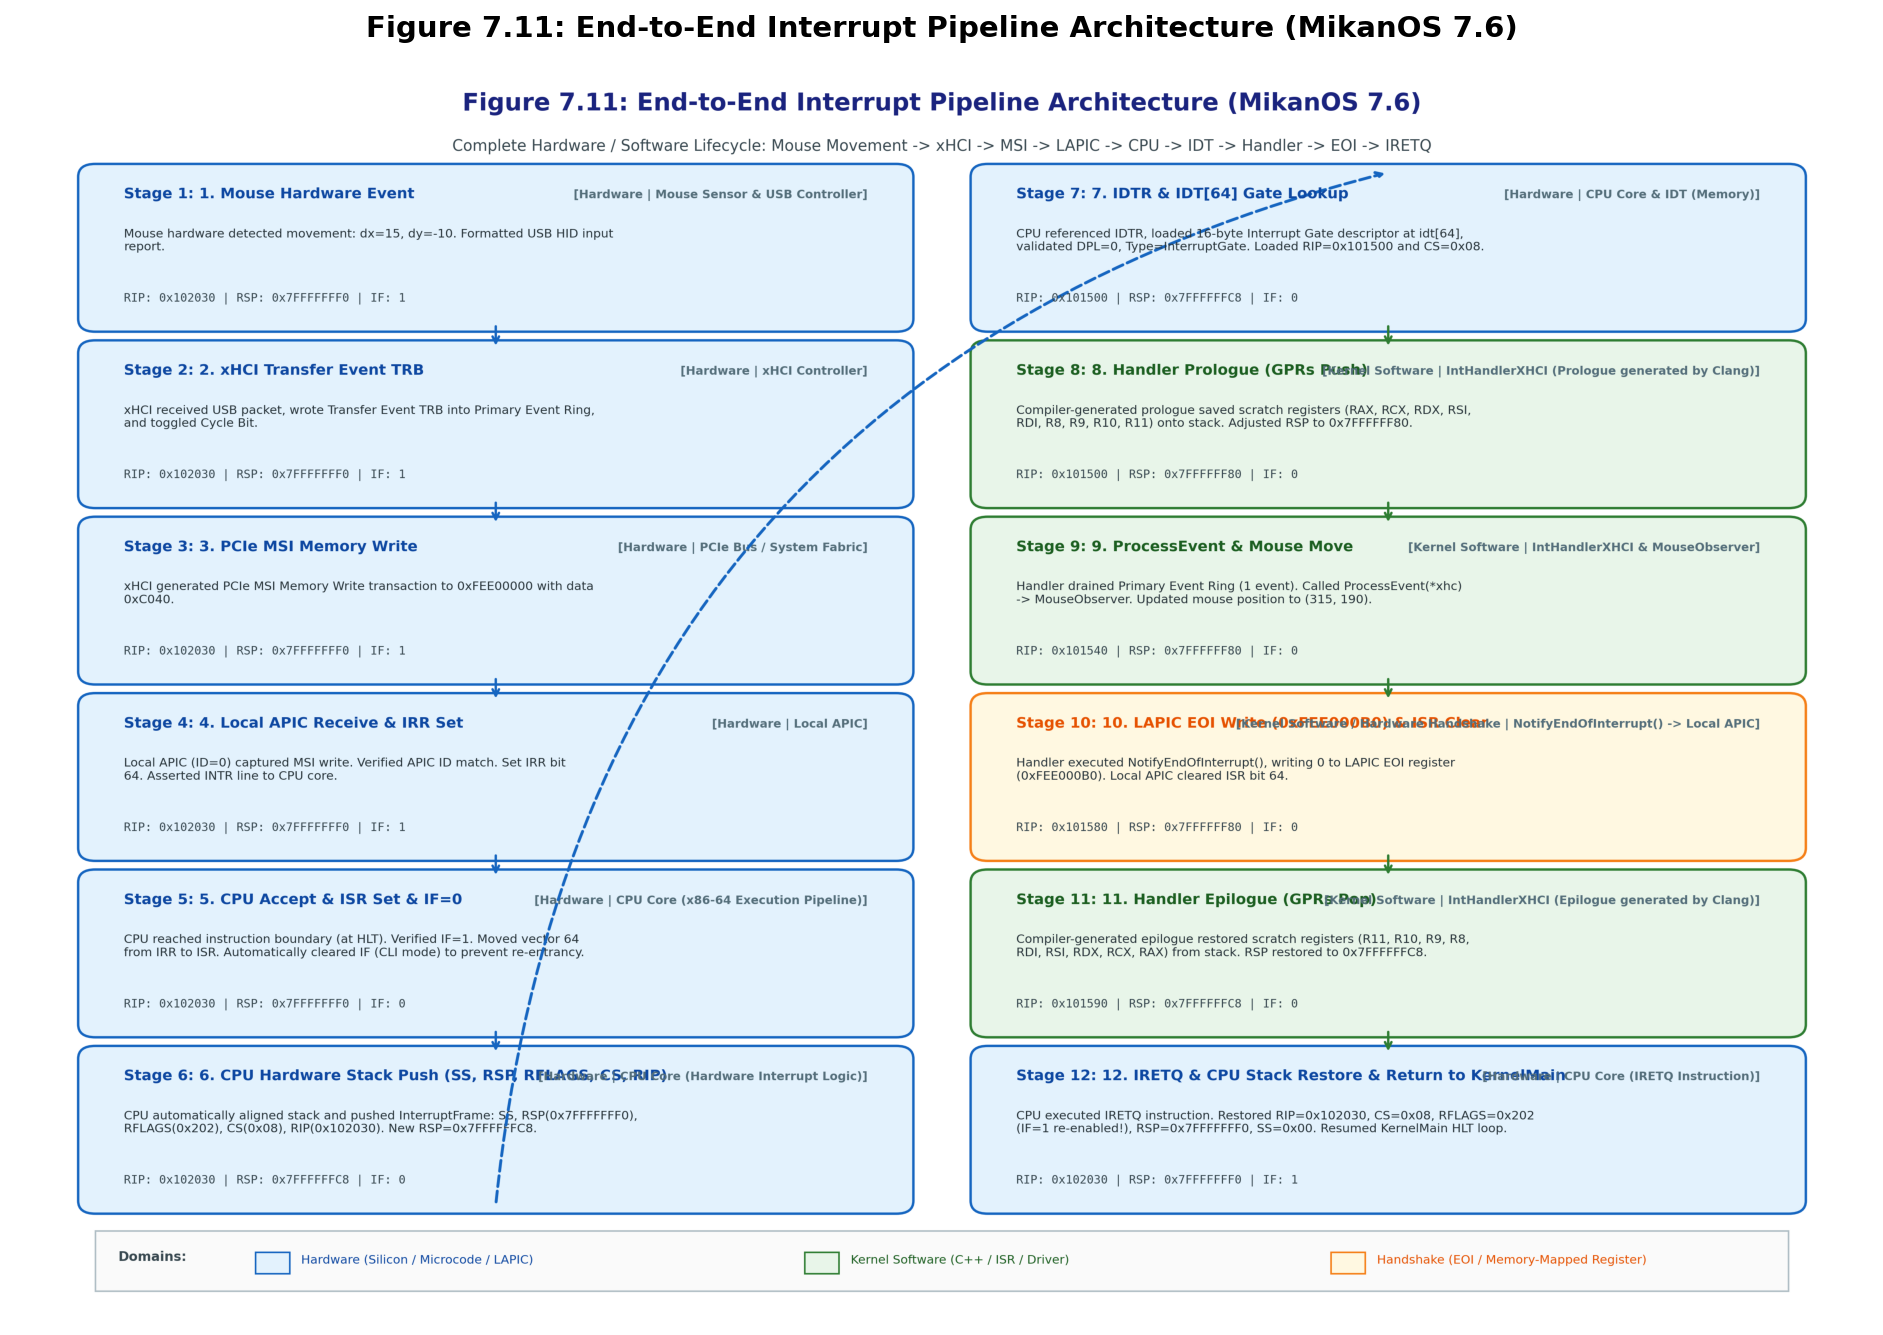

In [2]:
# === Figure 7.11: エンド・ツー・エンド割り込みパイプライン完全シーケンス図 ===
import os
import matplotlib.pyplot as plt
from PIL import Image
from common import plot_end_to_end_interrupt_pipeline_sequence

result_dir = "result" if os.path.exists("result") else "7/result"
os.makedirs(result_dir, exist_ok=True)
fig7_11_path = os.path.join(result_dir, "fig7_11_end_to_end_interrupt_pipeline_sequence.png")

plot_end_to_end_interrupt_pipeline_sequence(fig7_11_path)
print("✅ Figure 7.11 generated at:", fig7_11_path)

# Notebook インライン表示
img = Image.open(fig7_11_path)
plt.figure(figsize=(16, 11), dpi=150)
plt.imshow(img)
plt.axis("off")
plt.title("Figure 7.11: End-to-End Interrupt Pipeline Architecture (MikanOS 7.6)", fontsize=14, fontweight="bold")
plt.show()


✅ Figure 7.12 generated at: result/fig7_12_hardware_software_boundary_and_stack_lifecycle.png


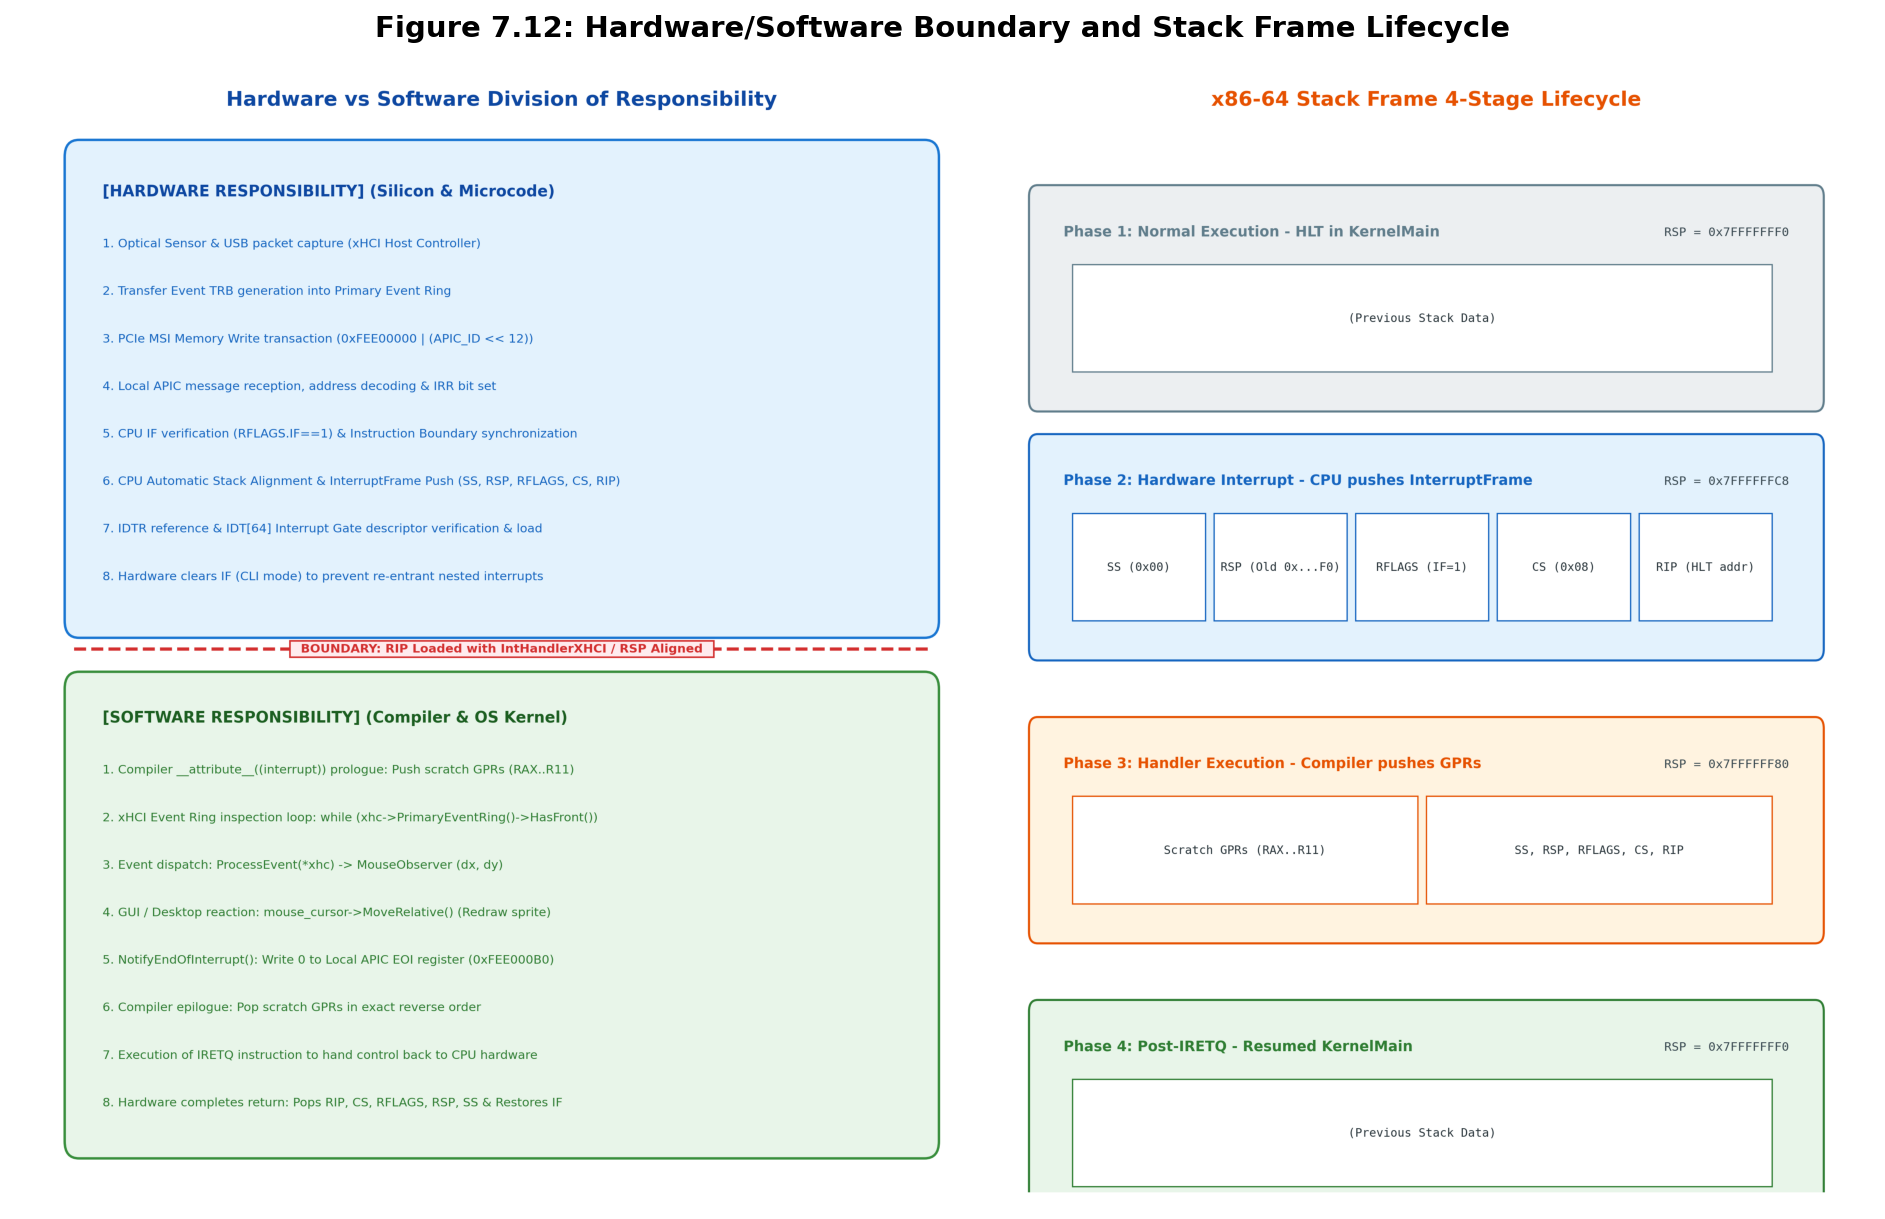

In [3]:
# === Figure 7.12: ハードウェア・ソフトウェア責任分界点とスタックフレーム4態ライフサイクル ===
from common import plot_hardware_software_boundary_and_stack_lifecycle

fig7_12_path = os.path.join(result_dir, "fig7_12_hardware_software_boundary_and_stack_lifecycle.png")

plot_hardware_software_boundary_and_stack_lifecycle(fig7_12_path)
print("✅ Figure 7.12 generated at:", fig7_12_path)

# Notebook インライン表示
img2 = Image.open(fig7_12_path)
plt.figure(figsize=(16, 10), dpi=150)
plt.imshow(img2)
plt.axis("off")
plt.title("Figure 7.12: Hardware/Software Boundary and Stack Frame Lifecycle", fontsize=14, fontweight="bold")
plt.show()


In [4]:
# === Python による 12 ステージ パイプライン対話型シミュレーション ===
from common import InterruptFlowPipelineSimulator

print("🚀 割り込みパイプラインシミュレータを初期化中...")
sim = InterruptFlowPipelineSimulator(
    bsp_apic_id=0,
    xhci_vector=0x40,
    initial_mouse=(300, 200),
    screen_size=(800, 600)
)

print(f"初期状態: マウス座標=({sim.mouse_x}, {sim.mouse_y}), RSP=0x{sim.rsp:X}, IF={1 if sim.rflags & 0x200 else 0}")
print("—" * 80)

# マウス変位イベントを発火 (dx=+25, dy=-15)
records = sim.trigger_mouse_movement(displacement_x=25, displacement_y=-15)

print(f"\n🎯 イベント発火: マウス変位 dx=+25, dy=-15 発生！ (全 {len(records)} ステージをトレース)\n")

for i, r in enumerate(records, start=1):
    domain_badge = f"[{r.domain:^16}]"
    print(f"Stage {i:2d}: {domain_badge} {r.component:<32}")
    print(f"         説明: {r.description}")
    print(f"         レジスタ: RIP=0x{r.rip:06X} | RSP=0x{r.rsp:09X} | IF={1 if r.rflags & 0x200 else 0}")
    print("—" * 80)

# 不変条件の自己検証
invariants = sim.verify_pipeline_invariants()
print("\n🔍 アーキテクチャ不変条件（Invariants）検証結果:")
for name, ok in invariants.items():
    status = "✅ PASS" if ok else "❌ FAIL"
    print(f"  - {name:<26}: {status}")

assert all(invariants.values()), "All pipeline invariants must hold!"
print(f"\n🎉 全ステージ検証完了！ 最終マウス座標: ({sim.mouse_x}, {sim.mouse_y})")


🚀 割り込みパイプラインシミュレータを初期化中...
初期状態: マウス座標=(300, 200), RSP=0x7FFFFFFF0, IF=1
————————————————————————————————————————————————————————————————————————————————

🎯 イベント発火: マウス変位 dx=+25, dy=-15 発生！ (全 12 ステージをトレース)

Stage  1: [    Hardware    ] Mouse Sensor & USB Controller   
         説明: Mouse hardware detected movement: dx=25, dy=-15. Formatted USB HID input report.
         レジスタ: RIP=0x102030 | RSP=0x7FFFFFFF0 | IF=1
————————————————————————————————————————————————————————————————————————————————
Stage  2: [    Hardware    ] xHCI Controller                 
         説明: xHCI received USB packet, wrote Transfer Event TRB into Primary Event Ring, and toggled Cycle Bit.
         レジスタ: RIP=0x102030 | RSP=0x7FFFFFFF0 | IF=1
————————————————————————————————————————————————————————————————————————————————
Stage  3: [    Hardware    ] PCIe Bus / System Fabric        
         説明: xHCI generated PCIe MSI Memory Write transaction to 0xFEE00000 with data 0xC040.
         レジスタ: RIP=0x102030 | RSP=0x7F

## 4. MikanOS カーネル実装コードとハードウェア動作の完全対照表

MikanOS（`osbook_day07a`）のソースコードのどの行が、ハードウェアのどの動作に対応しているかを対照表で確認します。

| ステージ | 対象ファイル / 関数 | C++ / アセンブリ実装行 | 対応するハードウェア動作 |
|:---:|:---|:---|:---|
| **事前設定 1** | `kernel/main.cpp`<br>`SetIDTEntry` | `SetIDTEntry(idt[InterruptVector::kXHCI], MakeIDTAttr(DescriptorType::kInterruptGate, 0), reinterpret_cast<uint64_t>(IntHandlerXHCI), cs);` | IDT の 64 番エントリにハンドラアドレスと CS を書き込み、Type=InterruptGate に設定 |
| **事前設定 2** | `kernel/main.cpp`<br>`LoadIDT` | `LoadIDT(sizeof(idt) - 1, reinterpret_cast<uintptr_t>(&idt[0]));` | `lidt` 命令を実行し、CPU の `IDTR` レジスタに IDT のリミットとベースアドレスを格納 |
| **事前設定 3** | `kernel/main.cpp`<br>`ConfigureMSI` | `pci::ConfigureMSIFixedDestination(*xhc_dev, bsp_local_apic_id, ...);` | xHCI の PCI コンフィギュレーション空間に MSI アドレス（`0xFEE00000`）とデータ（`0xC040`）を書き込み、MSI を有効化 |
| **割り込み許可** | `kernel/main.cpp` | `__asm__("sti");` | `sti` 命令を実行し、CPU の `RFLAGS.IF` を 1 にセットして外部割り込みの受付を開始 |
| **アイドル待機** | `kernel/main.cpp` | `while (1) __asm__("hlt");` | `hlt` 命令を実行し、割り込みが届くまで CPU コアを省電力スリープ状態に移行 |
| **ハード突入** | *(ハードウェア)* | *(CPU マイクロコード自動実行)* | `IF=0` にクリア、スタックに SS, RSP, RFLAGS, CS, RIP を push、`IDTR` から `idt[64]` を引いてハンドラへジャンプ |
| **レジスタ退避** | `kernel/main.cpp` | `__attribute__((interrupt)) void IntHandlerXHCI(InterruptFrame* frame)` | Clang コンパイラがハンドラ先頭にスクラッチ汎用レジスタの push コードを展開 |
| **イベント処理** | `kernel/main.cpp` | `while (xhc->PrimaryEventRing()->HasFront()) { ProcessEvent(*xhc); }` | xHCI の Event Ring を読み出し、`MouseObserver` を経由してマウスカーソルの旧背景復元と新位置描画を実行 |
| **EOI 通知** | `kernel/interrupt.cpp`<br>`NotifyEndOfInterrupt` | `volatile auto end_of_interrupt = reinterpret_cast<uint32_t*>(0xfee000b0); *end_of_interrupt = 0;` | Local APIC の EOI レジスタに 0 を書き込み、ISR レジスタのビット 64 をクリアして次の割り込みを許可 |
| **復帰** | *(コンパイラ / CPU)* | *(コンパイラ生成 epilogue + `iretq`)* | 汎用レジスタを pop 復元し、`iretq` 命令でスタックから RIP/CS/RFLAGS/RSP/SS を復元して `KernelMain` の `hlt` へ復帰 |


In [5]:
# === C++20 スタンドアロン検証コードのビルド & 実行 ===
import os
import subprocess

cpp_source = "../src/ch07/interrupt_flow_sim.cpp" if os.path.exists("../src/ch07/interrupt_flow_sim.cpp") else "src/ch07/interrupt_flow_sim.cpp"
bin_output = "/tmp/ch07_interrupt_flow_sim"

print(f"🔨 C++20 検証コードをコンパイル中: {cpp_source} -> {bin_output}")
compile_cmd = [
    "g++", "-std=c++20", "-O2", "-Wall", "-Wextra", "-pedantic",
    cpp_source, "-o", bin_output
]
subprocess.run(compile_cmd, check=True)

print("🚀 スタンドアロン検証スイートを実行します:\n")
res_exec = subprocess.run([bin_output], capture_output=True, text=True, check=True)
print(res_exec.stdout)
assert "ALL 7 TESTS PASSED SUCCESSFULLY!" in res_exec.stdout


🔨 C++20 検証コードをコンパイル中: ../src/ch07/interrupt_flow_sim.cpp -> /tmp/ch07_interrupt_flow_sim


🚀 スタンドアロン検証スイートを実行します:

 MikanOS Section 7.6: Interrupt Flow & Pipeline Verification
[Test 1] Verifying InterruptFrame layout and offsets...
  -> PASS: InterruptFrame is exactly 40 bytes with correct System V ABI alignment.
[Test 2] Verifying Local APIC MMIO and MSI Address/Data calculations...
  -> PASS: Local APIC address 0xfee03000, data 0xc040 correctly formatted.
[Test 3] Verifying 16-byte IDT Interrupt Gate descriptor...
  -> PASS: IDT descriptor correctly encodes 64-bit target address 0x101500.
[Test 4] Simulating complete 12-stage interrupt pipeline for single mouse event...
  -> PASS: All 12 stages recorded with correct transitions and state verification.
[Test 5] Verifying 16-byte stack alignment during interrupt handling...
  -> PASS: 16-byte stack alignment invariants strictly preserved across stages.
[Test 6] Verifying CLI/STI reentrancy prevention and IF flag restoration...
  -> PASS: CPU hardware correctly cleared IF during handler and restored upon IRETQ.
[Test 7] Verif

## 5. コラム 7.1: もし EOI を送り忘れたらどうなるか？（Local APIC デッドロックの罠）

### 🚨 Local APIC の ISR (In-Service Register) と優先度マスク
自作 OS の開発初心者が最も頻繁に遭遇する落とし穴の一つが、**「最初の 1 回だけマウスが動いて、その後一切反応しなくなる」** というバグです。その原因の 99% は **`NotifyEndOfInterrupt()` (EOI) の通知漏れ** にあります。

1. **Local APIC の優先度ブロック規則**:
   - Local APIC は、現在処理中の割り込みベクタ番号を **ISR レジスタ** に記録しています。
   - Local APIC のハードウェア仕様により、**「ISR に立っているビットのベクタ番号と同等またはそれ以下の優先度を持つ新規割り込みは、CPU コアへ配送せず保留（Mask）する」** という厳格なルールが存在します。
2. **EOI を送らないとどうなるか？**:
   - `NotifyEndOfInterrupt()` を呼び出さずにハンドラを抜けると、CPU コアは `iretq` で `KernelMain` に戻り、`RFLAGS.IF` も 1（許可）に戻ります。
   - しかし、**Local APIC 側の ISR レジスタにはベクタ 64 のビットが立ったまま** になっています。
   - 次にユーザーがマウスを動かしても、Local APIC は「Core 0 はまだベクタ 64 の処理を完了していない」と判断し、新規の割り込み信号（`INTR`）を CPU コアに絶対に送りません。
   - 結果として、マウスイベントは xHCI の Event Ring に溜まり続け、OS の画面上のカーソルは完全にフリーズします。
3. **安全策**:
   - 割り込みハンドラを書く際は、処理の成功・失敗・早期リターン（`return`）にかかわらず、ハンドラの終端で確実に `NotifyEndOfInterrupt()` を呼ぶ構造にする必要があります。


## 6. 理解度セルフチェック（確認問題）

本節で学んだハードウェア協調動作と割り込みライフサイクルの理解度を診断する 3 つの設問です。

---

### 【問題 1】(ハードウェアスタック退避)
x86-64 CPU は、割り込みを受け付けた際に自動的に `RFLAGS` レジスタをスタックへ保存します。なぜ関数の戻りアドレス（`RIP`）だけでなく `RFLAGS` までハードウェアが退避しなければならないのでしょうか？ その理由をプロセッサの実行状態保護の観点から説明せよ。

<details>
<summary>▶ 解答・解説（クリックで展開）</summary>

- **解答**:
  1. **条件分岐フラグの保護**: 割り込みは命令実行の合間に非同期に発生します。もし元のプログラムが `CMP` 命令を実行した直後に割り込みが入り、ハンドラ内の演算で `ZF`（ゼロフラグ）や `CF`（キャリーフラグ）などのステータスフラグが変更されると、復帰後の条件分岐（`JE`, `JNE` 等）が誤作動してしまうため。
  2. **割り込み許可フラグ (`IF`) の原状復帰**: 割り込み突入時に CPU は自動で `IF=0` にクリアします。復帰時に `IRETQ` 命令で `RFLAGS` をスタックから復元することで、割り込み前の元の割り込み許可状態（`IF=1`）をアトミックに完全復元するため。
</details>

---

### 【問題 2】(多重割り込みと IF フラグ)
MikanOS では IDT のエントリ属性として `DescriptorType::kInterruptGate` を指定しています。CPU が Interrupt Gate を通じて割り込みハンドラを呼び出した瞬間、CPU の `IF` フラグはどのように変化するか？ また、Trap Gate（`DescriptorType::kTrapGate`）を指定した場合との決定的な違いを答えよ。

<details>
<summary>▶ 解答・解説（クリックで展開）</summary>

- **解答**:
  - **Interrupt Gate**: ゲートを通過してハンドラへジャンプした瞬間、CPU ハードウェアが **自動的に `RFLAGS.IF` を 0 にクリア（`cli` 相当）** します。これにより多重割り込みが防止されます。
  - **Trap Gate との違い**: Trap Gate では `IF` フラグはクリアされず、元の値がそのまま維持されます。システムコールやブレークポイント例外（`INT 3`）など、ハンドラ実行中も他の外部割り込みを受け付けたい場合に Trap Gate が使用されます。
</details>

---

### 【問題 3】(責任分界点)
以下の動作のうち、**「CPU / ハードウェアが自動的に行う動作」** には `[HW]`、**「OS カーネルまたはコンパイラが実装・実行しなければならない動作」** には `[SW]` を付けよ。

1. `(   )` スタックポインタ `RSP` の 16 バイトアライメントと `InterruptFrame` の push
2. `(   )` スクラッチ汎用レジスタ（`RAX`〜`R11`）のスタックへの push 保存
3. `(   )` Local APIC の EOI レジスタ（`0xFEE000B0`）への `0` の書き込み
4. `(   )` `IDTR` に基づく `idt[vector]` の 16 バイトディスクリプタ検証と `RIP`/`CS` のロード
5. `(   )` `iretq` 命令によるスタックからの `RIP`, `CS`, `RFLAGS`, `RSP`, `SS` の復元

<details>
<summary>▶ 解答・解説（クリックで展開）</summary>

- **解答**:
  1. **`[HW]`**: CPU マイクロコードが自動で行う。
  2. **`[SW]`**: コンパイラ（`__attribute__((interrupt))`）が生成するコードが行う。
  3. **`[SW]`**: OS カーネル（`NotifyEndOfInterrupt()`）が明示的に行わなければならない。
  4. **`[HW]`**: CPU ハードウェアが自動で行う。
  5. **`[HW]`**: `iretq` 命令自体の実行指示は SW だが、5 つのレジスタ復元と `IF` フラグの復元処理自体は CPU ハードウェアが自動実行する。
</details>


## 7. まとめ & 次節への布石

### 📌 本節の重要ポイント総括
1. **12 ステージの完全パイプライン**:
   マウス移動 $\to$ xHCI Event Ring $\to$ PCIe MSI $\to$ Local APIC $\to$ CPU IF 確認 $\to$ ハードウェアスタック退避 $\to$ IDT 探索 $\to$ コンパイラ GPR 退避 $\to$ `ProcessEvent` $\to$ EOI 通知 $\to$ GPR 復帰 $\to$ `IRETQ` による `KernelMain` 復帰という全シーケンスを体系化した。
2. **ハードウェアとソフトウェアの協調の妙**:
   CPU は割り込み受付と同時に多重割り込みを防ぐため自動で `IF=0` にし、スタックを 16 バイト整列させて `InterruptFrame` を push する。OS はイベント処理後に EOI を通知し、`iretq` でハードウェアに制御を戻す。
3. **イベント駆動 OS の完成**:
   CPU は `while (1) __asm__("hlt");` で省電力停止し、マウスが動いた瞬間だけ割り込みで起床してピクセルを再描画する、現代的な OS の省電力実行モデルが確立された。

---

### 🗺️ 次節 7.7 へのロードマップ（残された課題）
第 7.6 節で割り込み駆動の全貌を明らかにしましたが、現在の実装（`osbook_day07a`）には **OS アーキテクチャ上の重大な欠陥** が残されています：

> [!WARNING]
> **現在の実装の致命的課題**:
> `IntHandlerXHCI` の中で直接 `ProcessEvent` を呼び、その中で `mouse_cursor->MoveRelative()` による画面ピクセル描画（矩形塗りつぶし・スプライト描画）を行っています。
> 画面描画は極めて重い処理です。しかもハンドラ実行中は `IF=0`（割り込み禁止）であるため、**描画を行っている間、他のすべてのハードウェア割り込み（今後のタイマやキーボード）が完全にブロックされてしまいます！**
> さらに、マウスを高速に動かすと Event Ring からイベントを拾い切れずにオーバーフローし、カーソルが引っかかる現象が発生します。

次節 **7.7「割り込みハンドラの高速化 (`osbook_day07b`)」** では、この問題を解決するため、割り込みハンドラを **「最小限のデータ受領のみを行う前半部（Top Half）」** と **「後でゆっくり描画を行う遅延処理部（Bottom Half）」** に分離する、OS の古典的名設計 **「割り込みコンテキストの分離」** に挑戦します！
